# Battery State of Health Approximation
## FC-FFNN vs RBF Network — Problem 2.1

**Dataset:** NASA Battery Discharge Dataset (real Li-Ion experimental data)  
**Task:** Function Approximation — predict State of Health (SoH%) from cycle number  
**Networks:** Fully Connected Feedforward Neural Network (FC-FFNN) + Radial Basis Function (RBF) Network  
**Extra:** Magnitude Pruning on FC-FFNN  

---

### Problem Statement
Given a sequence of battery discharge cycles, approximate the nonlinear degradation curve:

$$f: \text{cycle\_number} \rightarrow \text{SoH}(\%)$$

where $\text{SoH}(n) = \frac{C_n}{C_0} \times 100\%$, $C_n$ is capacity at cycle $n$, $C_0$ is initial capacity.

### Notebook Structure
0. **Part 0** — Function approximation demo on a synthetic curve
1. **Part 1** — Data extraction from raw CSV files → clean degradation curve
2. **Part 2** — FC-FFNN implementation, training, pruning, architecture study  
3. **Part 3** — RBF Network implementation, epsilon sensitivity, centers study  
4. **Part 4** — Final comparison: FC-FFNN vs RBF

## Part 0 — Function Approximation Demo

Before using real battery data, both networks are tested on a known synthetic function with added noise:

$$f(x) = \sin(2\pi x) + 0.3\cos(5\pi x), \quad x \in [0, 1]$$

**Universal Approximation Theorem (Cybenko, 1989 / Hornik, 1991):** a feedforward network with a single hidden layer, enough neurons and a non-linear activation (sigmoid, tanh, ReLU, ...) can approximate any continuous function on a compact subset of $\mathbb{R}^n$ to arbitrary precision.

What it does **not** tell us:
- How many neurons are actually needed (could be exponentially many)
- How to find/train those weights (convergence is not guaranteed)
- Whether the network will generalize beyond the training data
- How deep vs. wide networks compare in practice
- Anything about training speed or computational cost

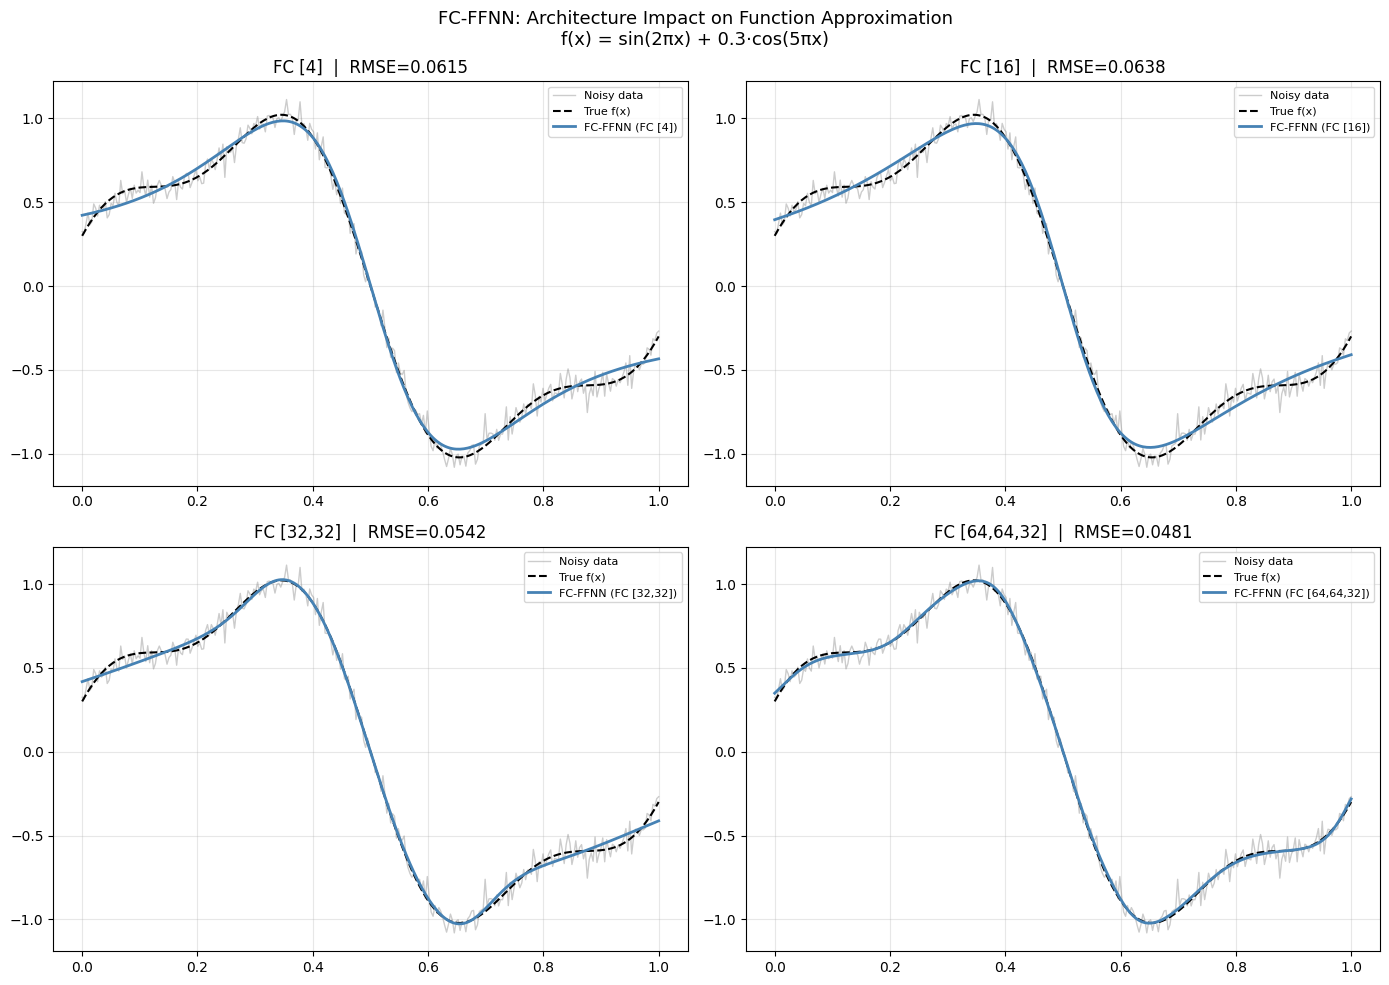

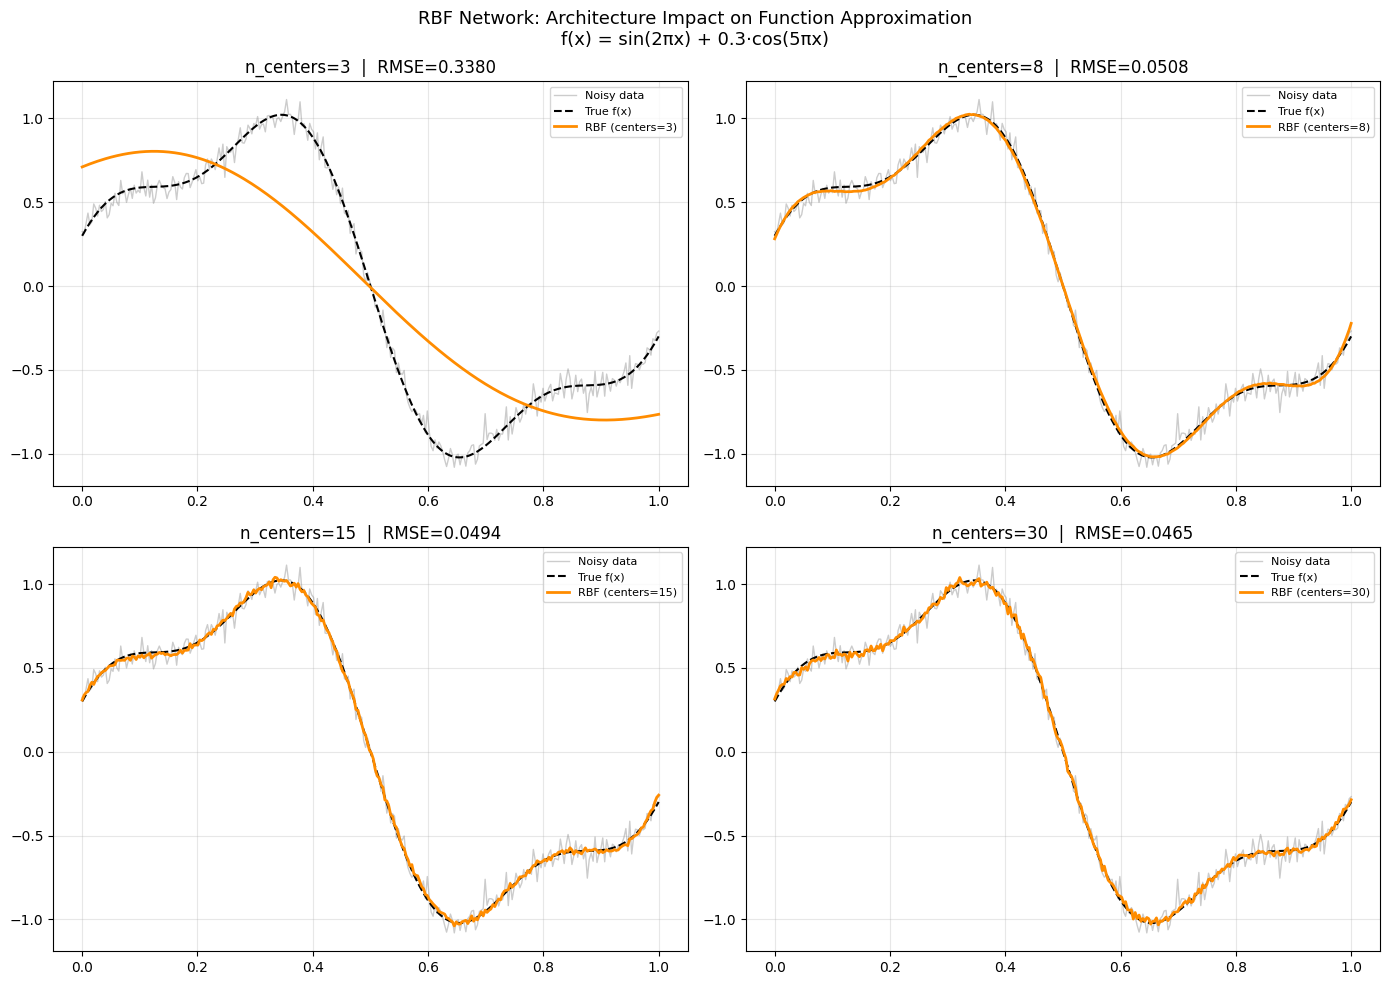

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error

IMAGES_DIR = 'images'
os.makedirs(IMAGES_DIR, exist_ok=True)

# ---- FC-FFNN class definition ----
class FCFFNN(nn.Module):
    def __init__(self, hidden_sizes=[64, 64, 32]):
        super(FCFFNN, self).__init__()
        layers = []
        in_size = 1
        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))
            layers.append(nn.Tanh())
            in_size = h
        layers.append(nn.Linear(in_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

# ---- RBF class definition ----
class RBFNetwork:
    def __init__(self, n_centers=20, epsilon=5.0):
        self.n_centers = n_centers
        self.epsilon   = epsilon
        self.centers   = None
        self.weights   = None

    def _gaussian(self, X, centers):
        diff = X[:, np.newaxis, :] - centers[np.newaxis, :, :]
        dist_sq = np.sum(diff**2, axis=2)
        return np.exp(-self.epsilon * dist_sq)

    def fit(self, X_train, y_train):
        kmeans = KMeans(n_clusters=self.n_centers, random_state=42, n_init=10)
        kmeans.fit(X_train)
        self.centers = kmeans.cluster_centers_
        Phi = self._gaussian(X_train, self.centers)
        Phi_bias = np.hstack([Phi, np.ones((Phi.shape[0], 1))])
        self.weights = np.linalg.lstsq(Phi_bias, y_train, rcond=None)[0]
        return self

    def predict(self, X):
        Phi = self._gaussian(X, self.centers)
        Phi_bias = np.hstack([Phi, np.ones((Phi.shape[0], 1))])
        return Phi_bias @ self.weights

# ---- Target function ----
np.random.seed(42)
X_func = np.linspace(0, 1, 300).reshape(-1, 1).astype(np.float32)
y_func = (np.sin(2 * np.pi * X_func) + 0.3 * np.cos(5 * np.pi * X_func)).astype(np.float32)
y_noisy = y_func + 0.05 * np.random.randn(*y_func.shape).astype(np.float32)

X_t = torch.FloatTensor(X_func)
y_t = torch.FloatTensor(y_noisy)

# ---- Train helper ----
def train_and_predict(hidden_sizes, X_t, y_t, epochs=2000, lr=0.01):
    torch.manual_seed(42)
    model = FCFFNN(hidden_sizes=hidden_sizes)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss_fn(model(X_t), y_t).backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        return model(X_t).numpy()

# ---- FC-FFNN architecture comparison ----
architectures_func = {
    'FC [4]':        [4],
    'FC [16]':       [16],
    'FC [32,32]':    [32, 32],
    'FC [64,64,32]': [64, 64, 32],
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('FC-FFNN: Architecture Impact on Function Approximation\nf(x) = sin(2πx) + 0.3·cos(5πx)', fontsize=13)

for ax, (name, hidden) in zip(axes.flatten(), architectures_func.items()):
    preds = train_and_predict(hidden, X_t, y_t)
    rmse = np.sqrt(mean_squared_error(y_noisy, preds))
    ax.plot(X_func, y_noisy, color='gray', alpha=0.4, linewidth=1, label='Noisy data')
    ax.plot(X_func, y_func,  color='black', linewidth=1.5, linestyle='--', label='True f(x)')
    ax.plot(X_func, preds,   color='steelblue', linewidth=2, label=f'FC-FFNN ({name})')
    ax.set_title(f'{name}  |  RMSE={rmse:.4f}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'function_approx_ffnn.png'), dpi=150, bbox_inches='tight')
plt.show()

# ---- RBF architecture comparison ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('RBF Network: Architecture Impact on Function Approximation\nf(x) = sin(2πx) + 0.3·cos(5πx)', fontsize=13)

rbf_configs = [(3, 5.0), (8, 5.0), (15, 5.0), (30, 5.0)]

for ax, (nc, eps) in zip(axes.flatten(), rbf_configs):
    m = RBFNetwork(n_centers=nc, epsilon=eps)
    m.fit(X_func, y_noisy)
    preds = m.predict(X_func)
    rmse = np.sqrt(mean_squared_error(y_noisy, preds))
    ax.plot(X_func, y_noisy, color='gray', alpha=0.4, linewidth=1, label='Noisy data')
    ax.plot(X_func, y_func,  color='black', linewidth=1.5, linestyle='--', label='True f(x)')
    ax.plot(X_func, preds,   color='darkorange', linewidth=2, label=f'RBF (centers={nc})')
    ax.set_title(f'n_centers={nc}  |  RMSE={rmse:.4f}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'function_approx_rbf.png'), dpi=150, bbox_inches='tight')
plt.show()

## Part 1 — Data Extraction

### What We Do
Each CSV file contains one full discharge cycle of a Li-Ion battery, recording:
- `Voltage_measured` — terminal voltage (V)
- `Current_measured` — discharge current (A, negative during discharge)
- `Temperature_measured` — cell temperature (°C)
- `Time` — elapsed time (seconds)

### Capacity Calculation
From each discharge file, we extract **one number** — the total capacity discharged (Ah):

$$C = \int_0^T |I(t)| \, dt \approx \sum_{k=1}^{N} |I_k| \cdot \Delta t_k$$

This is computed using the **trapezoidal rule** (numerical integration):

$$C \approx \frac{1}{3600} \sum_{k=1}^{N-1} \frac{|I_k| + |I_{k+1}|}{2} \cdot (t_{k+1} - t_k)$$

The factor $\frac{1}{3600}$ converts seconds to hours, giving capacity in **Ampere-hours (Ah)**.

### State of Health (SoH)
$$\text{SoH}(n) = \frac{C_n}{C_0} \times 100\%$$

where $C_0$ is the capacity at cycle 1 (fresh battery = 100% SoH).

In [2]:
import zipfile
import os

DATA_DIR = 'battery_data'       # raw discharge CSVs (extracted from battery_data.zip)
RESULTS_DIR = 'results'         # intermediate .npy / .csv outputs
IMAGES_DIR = 'images'           # figures used in the README

with zipfile.ZipFile('battery_data.zip', 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm  # progress bar

In [4]:
os.makedirs(RESULTS_DIR, exist_ok=True)

def extract_capacity(filepath):
    """
    From one discharge CSV, compute total capacity discharged (Ah).
    Capacity = integral of |current| over time  (trapezoidal rule)
    Current is negative during discharge, so we take absolute value.
    """
    try:
        df = pd.read_csv(filepath)

        # Make sure required columns exist
        required = ['Current_measured', 'Time']
        for col in required:
            if col not in df.columns:
                return None

        # Drop rows with NaN
        df = df[required].dropna()

        # Sort by time just in case
        df = df.sort_values('Time').reset_index(drop=True)

        # Time in seconds → convert to hours
        time_hours = df['Time'].values / 3600.0

        # Current in Amperes (negative during discharge → take abs)
        current = np.abs(df['Current_measured'].values)

        # Skip files where current is basically zero (not a discharge cycle)
        if current.mean() < 0.1:
            return None

        # Trapezoidal integration → capacity in Ah
        capacity = np.trapezoid(current, time_hours)

        return capacity

    except Exception as e:
        return None


# Get all CSV files sorted by name
all_files = sorted([
    f for f in os.listdir(DATA_DIR)
    if f.endswith('.csv')
])

print(f"Found {len(all_files)} CSV files")
print("Extracting capacity from each cycle...")

cycles = []
capacities = []

for i, filename in enumerate(tqdm(all_files)):
    filepath = os.path.join(DATA_DIR, filename)
    cap = extract_capacity(filepath)

    if cap is not None and cap > 0.1:  # filter out bad/empty files
        cycles.append(i + 1)
        capacities.append(cap)

print(f"\nSuccessfully extracted {len(cycles)} valid cycles")

Found 500 CSV files
Extracting capacity from each cycle...


100%|██████████| 500/500 [00:01<00:00, 279.20it/s]


Successfully extracted 394 valid cycles


In [5]:
cycles = np.array(cycles)
capacities = np.array(capacities)

# Normalize capacity to State of Health (SoH) in %
# SoH = capacity / initial_capacity * 100
initial_capacity = capacities[0]
soh = (capacities / initial_capacity) * 100.0

print(f"Initial capacity : {initial_capacity:.4f} Ah")
print(f"Final capacity   : {capacities[-1]:.4f} Ah")
print(f"Final SoH        : {soh[-1]:.2f}%")
print(f"Total cycles     : {len(cycles)}")

# Save to CSV
result_df = pd.DataFrame({
    'cycle': cycles,
    'capacity_ah': capacities,
    'soh_percent': soh
})

save_path = os.path.join(RESULTS_DIR, 'battery_degradation.csv')
result_df.to_csv(save_path, index=False)
print(f"\nSaved degradation data to: {save_path}")

Initial capacity : 1.7059 Ah
Final capacity   : 1.1585 Ah
Final SoH        : 67.91%
Total cycles     : 394

Saved degradation data to: results/battery_degradation.csv


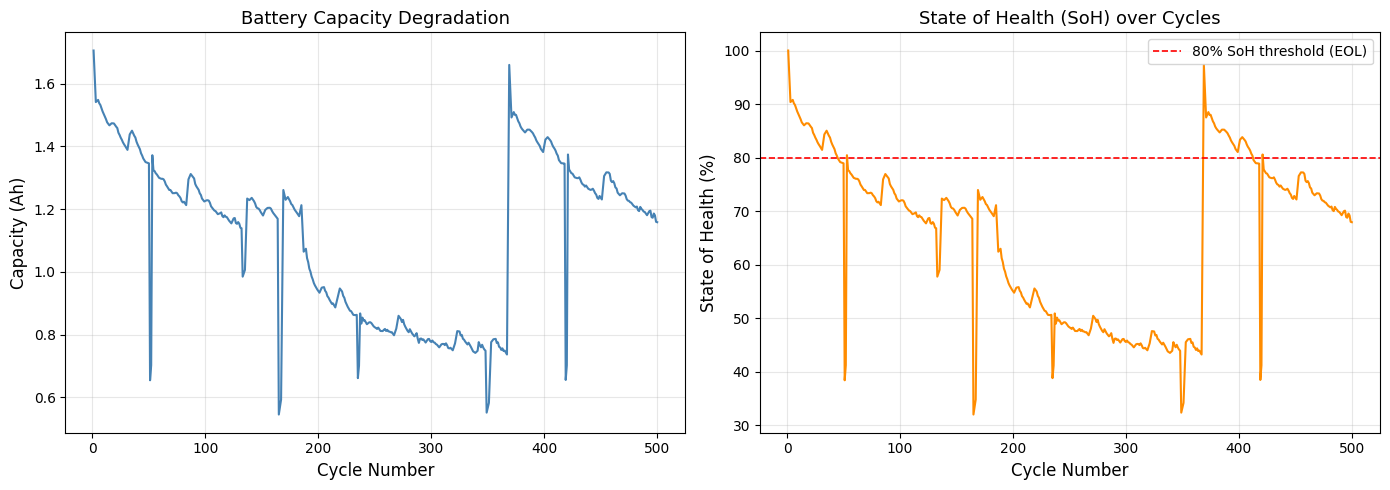

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Raw capacity
axes[0].plot(cycles, capacities, color='steelblue', linewidth=1.5)
axes[0].set_xlabel('Cycle Number', fontsize=12)
axes[0].set_ylabel('Capacity (Ah)', fontsize=12)
axes[0].set_title('Battery Capacity Degradation', fontsize=13)
axes[0].grid(True, alpha=0.3)

# Plot 2: State of Health %
axes[1].plot(cycles, soh, color='darkorange', linewidth=1.5)
axes[1].axhline(y=80, color='red', linestyle='--', linewidth=1.2, label='80% SoH threshold (EOL)')
axes[1].set_xlabel('Cycle Number', fontsize=12)
axes[1].set_ylabel('State of Health (%)', fontsize=12)
axes[1].set_title('State of Health (SoH) over Cycles', fontsize=13)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(IMAGES_DIR, 'degradation_curve.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()

Clean segment: 144 cycles
SoH range: 100.0% → 43.7%


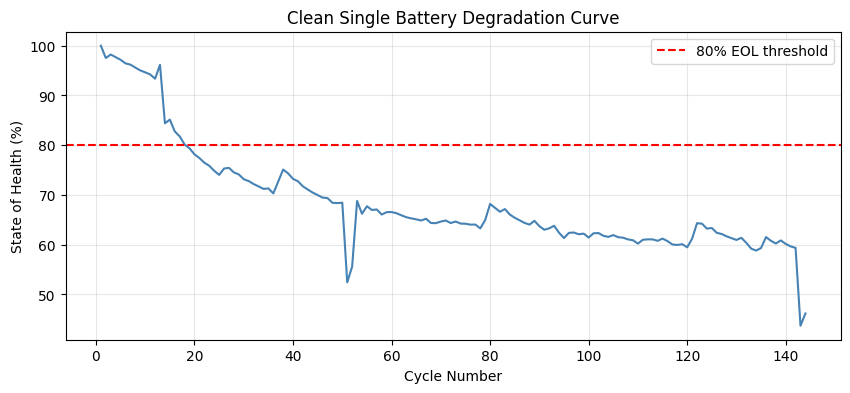

In [7]:
# Extract the best single battery segment
df_clean = result_df[(result_df.index >= 132) & (result_df.index < 276)].copy()
df_clean = df_clean.reset_index(drop=True)
df_clean['cycle'] = range(1, len(df_clean) + 1)

# Normalize SoH to start at 100%
df_clean['soh_percent'] = (df_clean['soh_percent'] / df_clean['soh_percent'].iloc[0]) * 100

print(f"Clean segment: {len(df_clean)} cycles")
print(f"SoH range: {df_clean['soh_percent'].max():.1f}% → {df_clean['soh_percent'].min():.1f}%")

# Plot it
plt.figure(figsize=(10, 4))
plt.plot(df_clean['cycle'], df_clean['soh_percent'], color='steelblue', linewidth=1.5)
plt.axhline(y=80, color='red', linestyle='--', label='80% EOL threshold')
plt.xlabel('Cycle Number')
plt.ylabel('State of Health (%)')
plt.title('Clean Single Battery Degradation Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(IMAGES_DIR, 'clean_soh_curve.png'), dpi=150, bbox_inches='tight')
plt.show()

df_clean.to_csv('battery_clean.csv', index=False)

## Part 2 — FC-FFNN (Fully Connected Feedforward Neural Network)

### Universal Approximation Theorem
**Theorem (Cybenko, 1989):** A feedforward neural network with a single hidden layer containing
a finite number of neurons can approximate any continuous function on compact subsets of $\mathbb{R}^n$
to arbitrary precision, given a non-polynomial activation function $\sigma$.

Formally: for any $f \in C([0,1]^n)$ and $\varepsilon > 0$, there exists $N$ and weights $\{w_i, b_i, c_i\}$ such that:

$$\left| f(x) - \sum_{i=1}^{N} c_i \cdot \sigma(w_i^T x + b_i) \right| < \varepsilon \quad \forall x \in [0,1]^n$$

**Practical limitations it does NOT address:**
- How many neurons $N$ are needed
- How to find the weights (training algorithm)  
- Whether gradient descent will converge
- Generalization to unseen data (overfitting)
- Computational cost

### Network Architecture
Our architecture: **Input(1) → Dense(64, Tanh) → Dense(64, Tanh) → Dense(32, Tanh) → Output(1)**

Forward pass at layer $l$:
$$h^{(l)} = \tanh\left(W^{(l)} h^{(l-1)} + b^{(l)}\right)$$

where $W^{(l)} \in \mathbb{R}^{n_l \times n_{l-1}}$ are weight matrices and $b^{(l)}$ are bias vectors.

**Why Tanh?**
- Bounded output in $(-1, 1)$ — matches normalized SoH range
- Smooth and differentiable everywhere — stable gradients
- Zero-centered — faster convergence than sigmoid

### Training: Backpropagation
Loss function (Mean Squared Error):
$$\mathcal{L} = \frac{1}{N} \sum_{i=1}^{N} (\hat{y}_i - y_i)^2$$

Gradient descent update (Adam optimizer):
$$\theta_{t+1} = \theta_t - \alpha \cdot \hat{m}_t / (\sqrt{\hat{v}_t} + \varepsilon)$$

where $\hat{m}_t$ and $\hat{v}_t$ are bias-corrected first and second moment estimates.

### Pruning: Magnitude-Based
After training, we remove the smallest weights (by absolute value).  
A weight $w_{ij}$ is pruned (set to zero) if:

$$|w_{ij}| < \tau$$

where $\tau$ is chosen so that exactly 30% of all weights are zeroed out.  
This exploits **network redundancy** — many weights contribute negligibly to the output.  
After pruning, we fine-tune for 300 epochs to recover any lost accuracy.

In [8]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

df = pd.read_csv('battery_clean.csv')
print(f"Loaded {len(df)} cycles")
print(df.head())

Loaded 144 cycles
   cycle  capacity_ah  soh_percent
0      1     1.261190   100.000000
1      2     1.230070    97.532445
2      3     1.238829    98.226984
3      4     1.232045    97.689060
4      5     1.225511    97.170969


In [9]:
# Input: cycle number, Output: SoH
X = df['cycle'].values.reshape(-1, 1).astype(np.float32)
y = df['soh_percent'].values.reshape(-1, 1).astype(np.float32)

# Normalize both to [0, 1]
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Train/test split (80/20) - keep order (no shuffle, time series)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_scaled, test_size=0.2, shuffle=False
)

# Convert to tensors
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.FloatTensor(y_train)
X_test_t  = torch.FloatTensor(X_test)
y_test_t  = torch.FloatTensor(y_test)
X_all_t   = torch.FloatTensor(X_scaled)

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 115, Test size: 29


In [10]:
class FCFFNN(nn.Module):
    """
    Fully Connected Feedforward Neural Network.
    Architecture: 1 -> hidden_sizes -> 1
    Activation: Tanh (good for smooth regression curves)
    """
    def __init__(self, hidden_sizes=[64, 64, 32]):
        super(FCFFNN, self).__init__()

        layers = []
        in_size = 1  # input: cycle number

        for h in hidden_sizes:
            layers.append(nn.Linear(in_size, h))
            layers.append(nn.Tanh())
            in_size = h

        layers.append(nn.Linear(in_size, 1))  # output: SoH
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

In [11]:
def train_model(model, X_train, y_train, epochs=1000, lr=0.01, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=300, gamma=0.5)

    losses = []
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output = model(X_train)
        loss = criterion(output, y_train)
        loss.backward()
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())

        if verbose and (epoch + 1) % 200 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6f}")

    return losses

In [12]:
torch.manual_seed(42)  # for reproducibility
model = FCFFNN(hidden_sizes=[64, 64, 32])
print(f"Model architecture:\n{model}")
print(f"Total parameters: {model.count_parameters()}")

print("\nTraining FC-FFNN...")
losses = train_model(model, X_train_t, y_train_t, epochs=1000, lr=0.01)

Model architecture:
FCFFNN(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Total parameters: 6401

Training FC-FFNN...
Epoch 200/1000 | Loss: 0.002032
Epoch 400/1000 | Loss: 0.001924
Epoch 600/1000 | Loss: 0.001878
Epoch 800/1000 | Loss: 0.001846
Epoch 1000/1000 | Loss: 0.001815


In [13]:
def evaluate_model(model, X_test_t, y_test_t, scaler_y, label="Model"):
    model.eval()
    with torch.no_grad():
        preds_scaled = model(X_test_t).numpy()
        preds = scaler_y.inverse_transform(preds_scaled)
        actual = scaler_y.inverse_transform(y_test_t.numpy())

    mse  = mean_squared_error(actual, preds)
    mae  = mean_absolute_error(actual, preds)
    rmse = np.sqrt(mse)
    print(f"\n{label} Performance:")
    print(f"  MSE  : {mse:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAE  : {mae:.4f}")
    return preds, actual, mse, rmse, mae

preds_before, actual, mse_before, rmse_before, mae_before = evaluate_model(
    model, X_test_t, y_test_t, scaler_y, "FC-FFNN (before pruning)"
)


FC-FFNN (before pruning) Performance:
  MSE  : 15.8762
  RMSE : 3.9845
  MAE  : 2.6117


In [14]:
import torch.nn.utils.prune as prune

def apply_pruning(model, pruning_amount=0.3):
    """
    Apply global unstructured magnitude pruning.
    pruning_amount: fraction of weights to zero out (0.3 = 30%)
    """
    # Collect all linear layers
    parameters_to_prune = []
    for module in model.modules():
        if isinstance(module, nn.Linear):
            parameters_to_prune.append((module, 'weight'))

    # Apply global magnitude pruning
    prune.global_unstructured(
        parameters_to_prune,
        pruning_method=prune.L1Unstructured,
        amount=pruning_amount,
    )
    return model

def count_zero_weights(model):
    total = 0
    zeros = 0
    for module in model.modules():
        if isinstance(module, nn.Linear):
            total += module.weight.nelement()
            zeros += (module.weight == 0).sum().item()
    return zeros, total

# Apply 30% pruning
model_pruned = FCFFNN(hidden_sizes=[64, 64, 32])
model_pruned.load_state_dict(model.state_dict())  # copy trained weights

print("\nApplying 30% magnitude pruning...")
model_pruned = apply_pruning(model_pruned, pruning_amount=0.3)

zeros, total = count_zero_weights(model_pruned)
print(f"Weights zeroed out: {zeros}/{total} ({100*zeros/total:.1f}%)")

# Evaluate after pruning
preds_after, _, mse_after, rmse_after, mae_after = evaluate_model(
    model_pruned, X_test_t, y_test_t, scaler_y, "FC-FFNN (after 30% pruning)"
)

# Fine-tune after pruning (helps recover accuracy)
print("\nFine-tuning pruned model for 300 epochs...")
train_model(model_pruned, X_train_t, y_train_t, epochs=300, lr=0.001, verbose=False)

preds_finetuned, _, mse_ft, rmse_ft, mae_ft = evaluate_model(
    model_pruned, X_test_t, y_test_t, scaler_y, "FC-FFNN (after pruning + fine-tune)"
)


Applying 30% magnitude pruning...
Weights zeroed out: 1872/6240 (30.0%)

FC-FFNN (after 30% pruning) Performance:
  MSE  : 20.5542
  RMSE : 4.5337
  MAE  : 2.5118

Fine-tuning pruned model for 300 epochs...

FC-FFNN (after pruning + fine-tune) Performance:
  MSE  : 15.7160
  RMSE : 3.9643
  MAE  : 2.3530


In [15]:
print("\nStudying architecture impact...")
architectures = {
    'Tiny [8]':          [8],
    'Small [16,16]':     [16, 16],
    'Medium [32,32]':    [32, 32],
    'Our [64,64,32]':    [64, 64, 32],
    'Large [128,64,32]': [128, 64, 32],
}

arch_results = {}
for name, hidden in architectures.items():
    torch.manual_seed(42)
    m = FCFFNN(hidden_sizes=hidden)
    train_model(m, X_train_t, y_train_t, epochs=1000, lr=0.01, verbose=False)
    m.eval()
    with torch.no_grad():
        p = scaler_y.inverse_transform(m(X_test_t).numpy())
        a = scaler_y.inverse_transform(y_test_t.numpy())
    rmse = np.sqrt(mean_squared_error(a, p))
    arch_results[name] = {'rmse': rmse, 'params': m.count_parameters()}
    print(f"  {name:25s} | RMSE: {rmse:.4f} | Params: {m.count_parameters()}")


Studying architecture impact...
  Tiny [8]                  | RMSE: 4.2989 | Params: 25
  Small [16,16]             | RMSE: 4.1112 | Params: 321
  Medium [32,32]            | RMSE: 4.3461 | Params: 1153
  Our [64,64,32]            | RMSE: 3.9845 | Params: 6401
  Large [128,64,32]         | RMSE: 4.0139 | Params: 10625


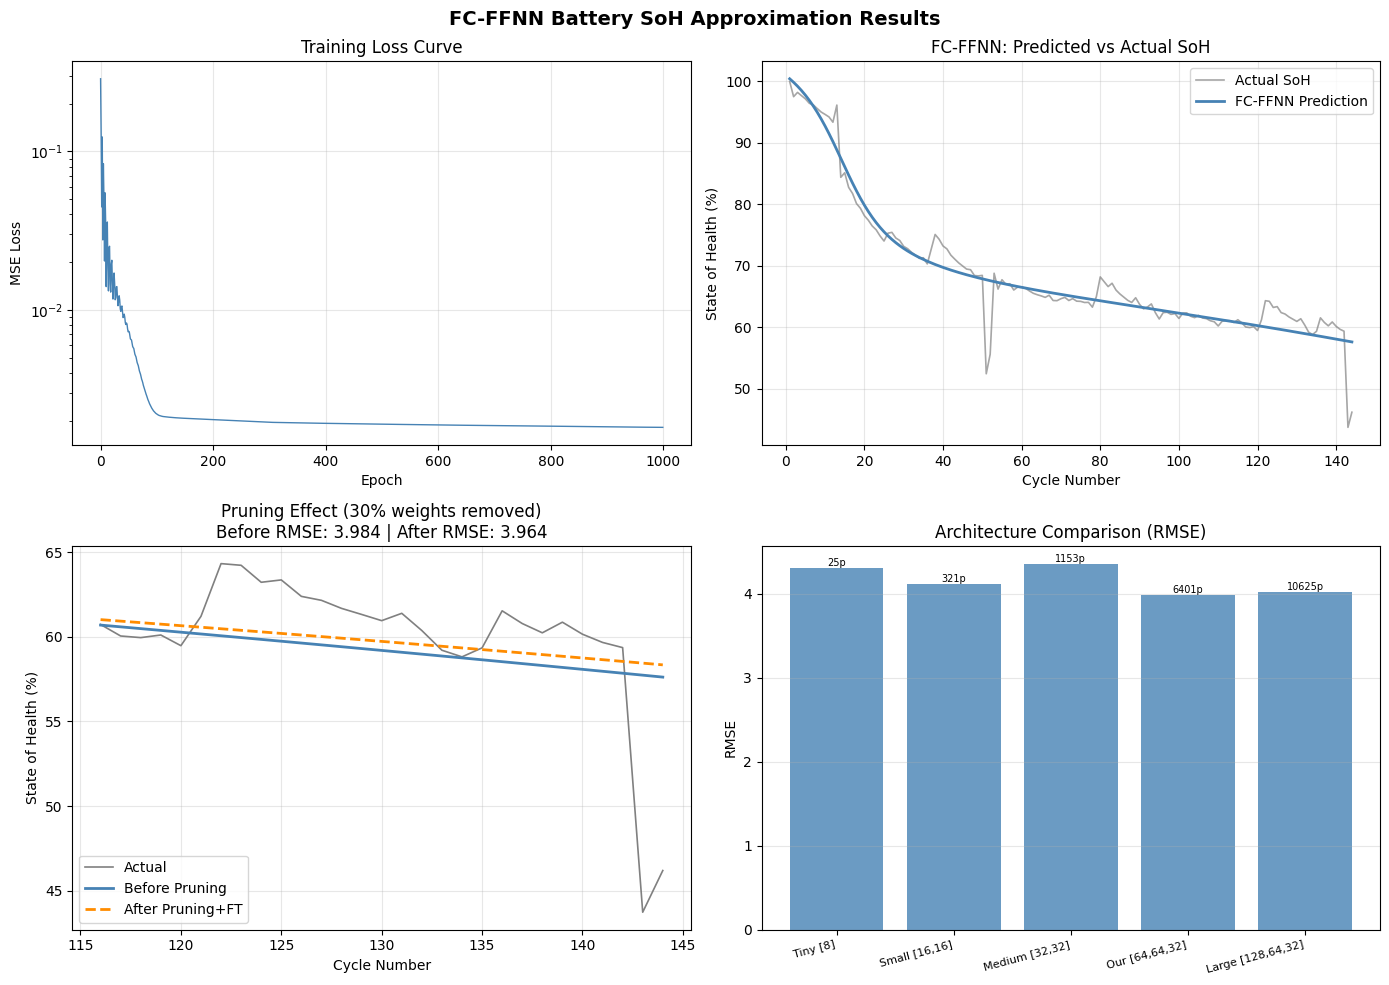

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('FC-FFNN Battery SoH Approximation Results', fontsize=14, fontweight='bold')

# --- Plot 1: Training loss ---
axes[0,0].plot(losses, color='steelblue', linewidth=1)
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('MSE Loss')
axes[0,0].set_title('Training Loss Curve')
axes[0,0].set_yscale('log')
axes[0,0].grid(True, alpha=0.3)

# --- Plot 2: Prediction vs Actual (full curve) ---
model.eval()
with torch.no_grad():
    full_pred_scaled = model(X_all_t).numpy()
full_pred = scaler_y.inverse_transform(full_pred_scaled)
full_actual = scaler_y.inverse_transform(y_scaled)

axes[0,1].plot(X, full_actual, label='Actual SoH', color='gray', linewidth=1.2, alpha=0.7)
axes[0,1].plot(X, full_pred,   label='FC-FFNN Prediction', color='steelblue', linewidth=2)
axes[0,1].set_xlabel('Cycle Number')
axes[0,1].set_ylabel('State of Health (%)')
axes[0,1].set_title('FC-FFNN: Predicted vs Actual SoH')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# --- Plot 3: Before vs After pruning ---
test_cycles = X[len(X_train):]
axes[1,0].plot(test_cycles, actual,        label='Actual',          color='gray',       linewidth=1.2)
axes[1,0].plot(test_cycles, preds_before,  label='Before Pruning',  color='steelblue',  linewidth=2)
axes[1,0].plot(test_cycles, preds_finetuned, label='After Pruning+FT', color='darkorange', linewidth=2, linestyle='--')
axes[1,0].set_xlabel('Cycle Number')
axes[1,0].set_ylabel('State of Health (%)')
axes[1,0].set_title(f'Pruning Effect (30% weights removed)\nBefore RMSE: {rmse_before:.3f} | After RMSE: {rmse_ft:.3f}')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# --- Plot 4: Architecture comparison ---
names  = list(arch_results.keys())
rmses  = [arch_results[n]['rmse'] for n in names]
params = [arch_results[n]['params'] for n in names]
x_pos  = range(len(names))
bars = axes[1,1].bar(x_pos, rmses, color='steelblue', alpha=0.8)
axes[1,1].set_xticks(x_pos)
axes[1,1].set_xticklabels(names, rotation=15, ha='right', fontsize=8)
axes[1,1].set_ylabel('RMSE')
axes[1,1].set_title('Architecture Comparison (RMSE)')
axes[1,1].grid(True, alpha=0.3, axis='y')
for bar, p in zip(bars, params):
    axes[1,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                   f'{p}p', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'fcffnn_results.png'), dpi=150, bbox_inches='tight')
plt.show()

In [17]:
print("\n" + "="*50)
print("FC-FFNN SUMMARY")
print("="*50)
print(f"Architecture      : [1] -> [64] -> [64] -> [32] -> [1]")
print(f"Activation        : Tanh")
print(f"Total parameters  : {model.count_parameters()}")
print(f"Training epochs   : 1000")
print(f"Optimizer         : Adam (lr=0.01)")
print(f"\nBefore pruning:")
print(f"  RMSE: {rmse_before:.4f}  MAE: {mae_before:.4f}")
print(f"\nAfter 30% pruning + fine-tune:")
print(f"  RMSE: {rmse_ft:.4f}  MAE: {mae_ft:.4f}")
print(f"\nWeights pruned    : 30% (zeroed out)")
print("="*50)

# Save model predictions for comparison in Part 4
os.makedirs(RESULTS_DIR, exist_ok=True)
np.save(os.path.join(RESULTS_DIR, 'fcffnn_predictions.npy'), full_pred)
np.save(os.path.join(RESULTS_DIR, 'actual_soh.npy'), full_actual)
np.save(os.path.join(RESULTS_DIR, 'cycles.npy'), X)


FC-FFNN SUMMARY
Architecture      : [1] -> [64] -> [64] -> [32] -> [1]
Activation        : Tanh
Total parameters  : 6401
Training epochs   : 1000
Optimizer         : Adam (lr=0.01)

Before pruning:
  RMSE: 3.9845  MAE: 2.6117

After 30% pruning + fine-tune:
  RMSE: 3.9643  MAE: 2.3530

Weights pruned    : 30% (zeroed out)


## Part 3 — RBF (Radial Basis Function) Network

### Architecture
An RBF network has 3 layers:
1. **Input layer** — receives cycle number $x$
2. **RBF hidden layer** — $K$ neurons, each computing a Gaussian kernel response
3. **Linear output layer** — weighted sum of RBF activations

### Gaussian Kernel (Activation Function)
Each hidden neuron $k$ responds to input $x$ based on distance from its center $\mu_k$:

$$\phi_k(x) = \exp\left(-\varepsilon \cdot \|x - \mu_k\|^2\right)$$

where:
- $\mu_k \in \mathbb{R}$ is the **center** of the $k$-th RBF neuron
- $\varepsilon > 0$ is the **shape parameter** controlling Gaussian width
- Small $\varepsilon$ → wide, smooth Gaussians; Large $\varepsilon$ → narrow, peaked Gaussians

### Step 1: Center Selection via K-Means
Centers $\{\mu_k\}_{k=1}^{K}$ are found by k-means clustering on training inputs.  
K-means minimizes within-cluster variance:
$$\min_{\{\mu_k\}} \sum_{k=1}^{K} \sum_{x_i \in S_k} \|x_i - \mu_k\|^2$$

This places centers where data is most dense — ideal for RBF approximation.

### Step 2: Design Matrix
For all training points, compute the activation matrix $\Phi \in \mathbb{R}^{N \times K}$:
$$\Phi_{ik} = \phi_k(x_i) = \exp\left(-\varepsilon \cdot \|x_i - \mu_k\|^2\right)$$

Add a bias column: $\tilde{\Phi} = [\Phi \; | \; \mathbf{1}] \in \mathbb{R}^{N \times (K+1)}$

### Step 3: Analytical Weight Solution (Least Squares)
Unlike FC-FFNN, output weights are solved analytically — **no backpropagation needed!**

Minimize: $\mathcal{L} = \|\tilde{\Phi} W - y\|^2$

Setting $\nabla_W \mathcal{L} = 0$:
$$W = (\tilde{\Phi}^T \tilde{\Phi})^{-1} \tilde{\Phi}^T y$$

In practice, we use `numpy.linalg.lstsq` for numerical stability.

### Epsilon (ε) Sensitivity — The Conditioning Dilemma
When $\varepsilon$ is too large, the Gaussian kernels become very narrow.  
The columns of $\Phi$ become nearly orthogonal (each center only activates for nearby points).  
The matrix $\tilde{\Phi}^T \tilde{\Phi}$ becomes **ill-conditioned** (near-singular).  
This causes $(\tilde{\Phi}^T \tilde{\Phi})^{-1}$ to have huge entries → catastrophically large weights → test RMSE above 200.

**Observed in our experiment (test RMSE):**
- $K = 5,\ \varepsilon = 0.1$ → RMSE = **4.65** ✅ (best configuration)
- $K = 20,\ \varepsilon = 5.0$ → RMSE = **202.9** ❌ (ill-conditioned)

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

df = pd.read_csv('battery_clean.csv')

# Input / output
X = df['cycle'].values.reshape(-1, 1).astype(np.float32)
y = df['soh_percent'].values.reshape(-1, 1).astype(np.float32)

# Normalize
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Train/test split (same as Part 2 — no shuffle)
split = int(0.8 * len(X_scaled))
X_train = X_scaled[:split]
y_train = y_scaled[:split]
X_test  = X_scaled[split:]
y_test  = y_scaled[split:]

print(f"Loaded {len(df)} cycles")
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

Loaded 144 cycles
Train: 115, Test: 29


In [19]:
class RBFNetwork:
    """
    Radial Basis Function Network.

    Architecture:
      Input → RBF Hidden Layer (Gaussian kernels) → Linear Output

    How it works:
      1. Centers (mu) are chosen via k-means clustering on training data
      2. Each hidden neuron computes: phi(x) = exp(-epsilon * ||x - mu||^2)
      3. Output is a linear combination of RBF activations: y = W * phi(x) + b
      4. Output weights W are solved analytically (least squares) — no backprop needed!

    Parameters:
      n_centers : number of RBF neurons (hidden layer size)
      epsilon   : shape parameter — controls width of each Gaussian
    """

    def __init__(self, n_centers=20, epsilon=5.0):
        self.n_centers = n_centers
        self.epsilon   = epsilon
        self.centers   = None   # shape: (n_centers, n_features)
        self.weights   = None   # output layer weights (solved analytically)

    def _gaussian(self, X, centers):
        """
        Compute RBF activation matrix.
        For each sample x and each center mu:
          phi(x, mu) = exp(-epsilon * ||x - mu||^2)
        Returns matrix of shape (n_samples, n_centers)
        """
        # X: (n_samples, 1), centers: (n_centers, 1)
        diff = X[:, np.newaxis, :] - centers[np.newaxis, :, :]  # (n, k, 1)
        dist_sq = np.sum(diff**2, axis=2)                        # (n, k)
        return np.exp(-self.epsilon * dist_sq)                   # (n, k)

    def fit(self, X_train, y_train):
        """
        Train the RBF network:
        Step 1 — Find centers using k-means
        Step 2 — Compute RBF activations for all training points
        Step 3 — Solve for output weights using least squares
        """
        # Step 1: k-means to find centers
        kmeans = KMeans(n_clusters=self.n_centers, random_state=42, n_init=10)
        kmeans.fit(X_train)
        self.centers = kmeans.cluster_centers_  # (n_centers, 1)

        # Step 2: compute activation matrix (design matrix)
        Phi = self._gaussian(X_train, self.centers)  # (n_train, n_centers)

        # Add bias column
        Phi_bias = np.hstack([Phi, np.ones((Phi.shape[0], 1))])

        # Step 3: solve W = (Phi^T Phi)^-1 Phi^T y  (least squares)
        self.weights = np.linalg.lstsq(Phi_bias, y_train, rcond=None)[0]

        return self

    def predict(self, X):
        """Forward pass: compute RBF activations then linear output"""
        Phi = self._gaussian(X, self.centers)
        Phi_bias = np.hstack([Phi, np.ones((Phi.shape[0], 1))])
        return Phi_bias @ self.weights

    def count_parameters(self):
        """Total trainable parameters"""
        # centers: n_centers * n_features
        # weights: n_centers + 1 (bias)
        return self.n_centers * self.centers.shape[1] + (self.n_centers + 1)

In [20]:
def evaluate_rbf(model, X_test, y_test, scaler_y, label="RBF"):
    preds_scaled = model.predict(X_test)
    preds  = scaler_y.inverse_transform(preds_scaled)
    actual = scaler_y.inverse_transform(y_test)
    mse    = mean_squared_error(actual, preds)
    rmse   = np.sqrt(mse)
    mae    = mean_absolute_error(actual, preds)
    print(f"\n{label}:")
    print(f"  MSE  : {mse:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAE  : {mae:.4f}")
    return preds, actual, mse, rmse, mae

# Train our main RBF model
rbf = RBFNetwork(n_centers=20, epsilon=5.0)
rbf.fit(X_train, y_train)
print(f"RBF trained! Centers: {rbf.n_centers}, Epsilon: {rbf.epsilon}")
print(f"Parameters: {rbf.count_parameters()}")

preds_rbf, actual, mse_rbf, rmse_rbf, mae_rbf = evaluate_rbf(
    rbf, X_test, y_test, scaler_y, "RBF (n_centers=20, epsilon=5.0)"
)

RBF trained! Centers: 20, Epsilon: 5.0
Parameters: 41

RBF (n_centers=20, epsilon=5.0):
  MSE  : 41172.9914
  RMSE : 202.9113
  MAE  : 141.7522


In [21]:
print("\nStudying effect of number of centers...")
centers_list = [3, 5, 10, 15, 20, 30, 40, 50]
center_results = {}

for nc in centers_list:
    m = RBFNetwork(n_centers=nc, epsilon=5.0)
    m.fit(X_train, y_train)
    p = scaler_y.inverse_transform(m.predict(X_test))
    a = scaler_y.inverse_transform(y_test)
    rmse = np.sqrt(mean_squared_error(a, p))
    center_results[nc] = rmse
    print(f"  Centers: {nc:3d} | RMSE: {rmse:.4f} | Params: {m.count_parameters()}")


Studying effect of number of centers...
  Centers:   3 | RMSE: 25.8643 | Params: 7
  Centers:   5 | RMSE: 7.9408 | Params: 11
  Centers:  10 | RMSE: 204.3570 | Params: 21
  Centers:  15 | RMSE: 190.7221 | Params: 31
  Centers:  20 | RMSE: 202.9113 | Params: 41
  Centers:  30 | RMSE: 220.7984 | Params: 61
  Centers:  40 | RMSE: 338.7246 | Params: 81
  Centers:  50 | RMSE: 332.9884 | Params: 101


In [22]:
print("\nStudying effect of epsilon (shape parameter)...")
epsilon_list = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0]
epsilon_results = {}

for eps in epsilon_list:
    m = RBFNetwork(n_centers=20, epsilon=eps)
    m.fit(X_train, y_train)
    p = scaler_y.inverse_transform(m.predict(X_test))
    a = scaler_y.inverse_transform(y_test)
    rmse = np.sqrt(mean_squared_error(a, p))
    epsilon_results[eps] = rmse
    print(f"  Epsilon: {eps:6.1f} | RMSE: {rmse:.4f}")


Studying effect of epsilon (shape parameter)...
  Epsilon:    0.1 | RMSE: 5.0715
  Epsilon:    0.5 | RMSE: 12.3101
  Epsilon:    1.0 | RMSE: 13.8176
  Epsilon:    2.0 | RMSE: 5.3763
  Epsilon:    5.0 | RMSE: 202.9113
  Epsilon:   10.0 | RMSE: 74.6074
  Epsilon:   20.0 | RMSE: 1438.1742
  Epsilon:   50.0 | RMSE: 586.8834


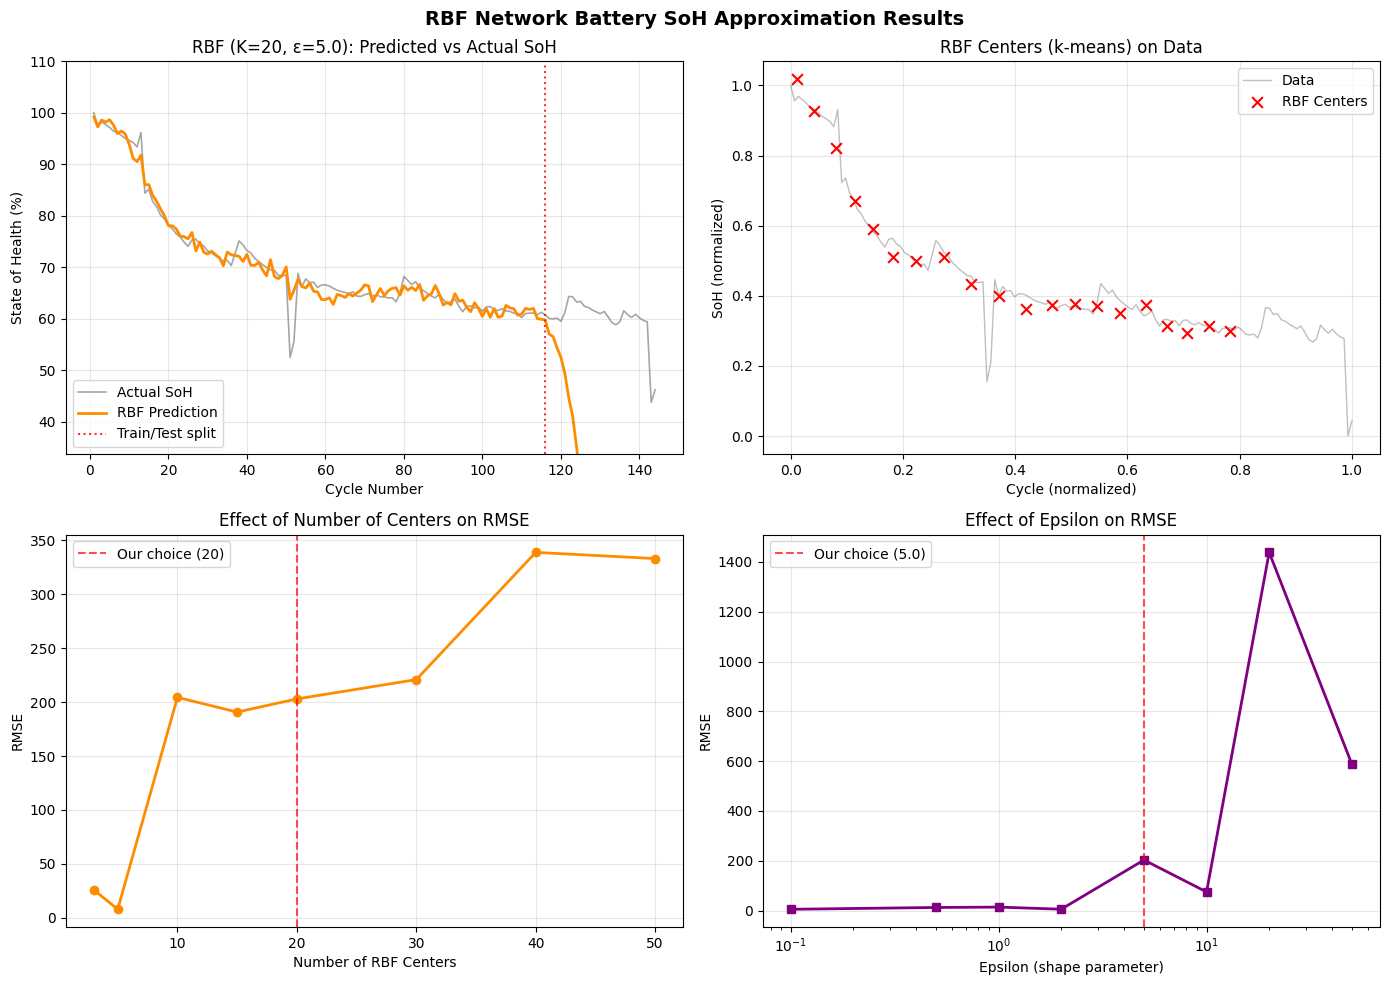

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('RBF Network Battery SoH Approximation Results', fontsize=14, fontweight='bold')

# Full prediction curve (model trained on the training split only)
full_pred_rbf_scaled = rbf.predict(X_scaled)
full_pred_rbf = scaler_y.inverse_transform(full_pred_rbf_scaled)
full_actual   = scaler_y.inverse_transform(y_scaled)

# --- Plot 1: Predicted vs Actual ---
axes[0,0].plot(X, full_actual,   label='Actual SoH',      color='gray',      linewidth=1.2, alpha=0.7)
axes[0,0].plot(X, full_pred_rbf, label='RBF Prediction',  color='darkorange', linewidth=2)
axes[0,0].set_xlabel('Cycle Number')
axes[0,0].set_ylabel('State of Health (%)')
axes[0,0].axvline(x=X[split, 0], color='red', linestyle=':', alpha=0.8, label='Train/Test split')
axes[0,0].set_ylim(full_actual.min() - 10, full_actual.max() + 10)  # test-region blow-up goes off-scale
axes[0,0].set_title('RBF (K=20, ε=5.0): Predicted vs Actual SoH')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# --- Plot 2: RBF centers visualization ---
axes[0,1].plot(X_scaled, y_scaled, color='gray', linewidth=1, alpha=0.5, label='Data')
axes[0,1].scatter(rbf.centers, rbf.predict(rbf.centers)[:,0],
                  color='red', zorder=5, s=60, label='RBF Centers', marker='x')
axes[0,1].set_xlabel('Cycle (normalized)')
axes[0,1].set_ylabel('SoH (normalized)')
axes[0,1].set_title('RBF Centers (k-means) on Data')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# --- Plot 3: Effect of number of centers ---
nc_vals   = list(center_results.keys())
rmse_vals = list(center_results.values())
axes[1,0].plot(nc_vals, rmse_vals, 'o-', color='darkorange', linewidth=2, markersize=6)
axes[1,0].axvline(x=20, color='red', linestyle='--', alpha=0.7, label='Our choice (20)')
axes[1,0].set_xlabel('Number of RBF Centers')
axes[1,0].set_ylabel('RMSE')
axes[1,0].set_title('Effect of Number of Centers on RMSE')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# --- Plot 4: Effect of epsilon ---
eps_vals  = list(epsilon_results.keys())
rmse_eps  = list(epsilon_results.values())
axes[1,1].plot(eps_vals, rmse_eps, 's-', color='purple', linewidth=2, markersize=6)
axes[1,1].axvline(x=5.0, color='red', linestyle='--', alpha=0.7, label='Our choice (5.0)')
axes[1,1].set_xlabel('Epsilon (shape parameter)')
axes[1,1].set_ylabel('RMSE')
axes[1,1].set_title('Effect of Epsilon on RMSE')
axes[1,1].set_xscale('log')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'rbf_results.png'), dpi=150, bbox_inches='tight')
plt.show()

In [24]:
print("\n" + "="*50)
print("RBF NETWORK SUMMARY")
print("="*50)
print(f"Architecture    : Input -> RBF(20 Gaussians) -> Linear Output")
print(f"Centers method  : K-means clustering")
print(f"Epsilon         : 5.0")
print(f"Parameters      : {rbf.count_parameters()}")
print(f"Training method : Least squares (analytical, no backprop)")
print(f"\nTest Performance:")
print(f"  MSE  : {mse_rbf:.4f}")
print(f"  RMSE : {rmse_rbf:.4f}")
print(f"  MAE  : {mae_rbf:.4f}")
print("="*50)


RBF NETWORK SUMMARY
Architecture    : Input -> RBF(20 Gaussians) -> Linear Output
Centers method  : K-means clustering
Epsilon         : 5.0
Parameters      : 41
Training method : Least squares (analytical, no backprop)

Test Performance:
  MSE  : 41172.9914
  RMSE : 202.9113
  MAE  : 141.7522


### Best RBF configuration

The studies above show that $K = 20,\ \varepsilon = 5.0$ is badly ill-conditioned. The best setting found is $K = 5,\ \varepsilon = 0.1$. It is trained on the **training split only**, and its predictions over all cycles are what Part 4 compares against the FC-FFNN.


RBF Best (n_centers=5, epsilon=0.1):
  MSE  : 21.5915
  RMSE : 4.6467
  MAE  : 4.0273
  Params: 11


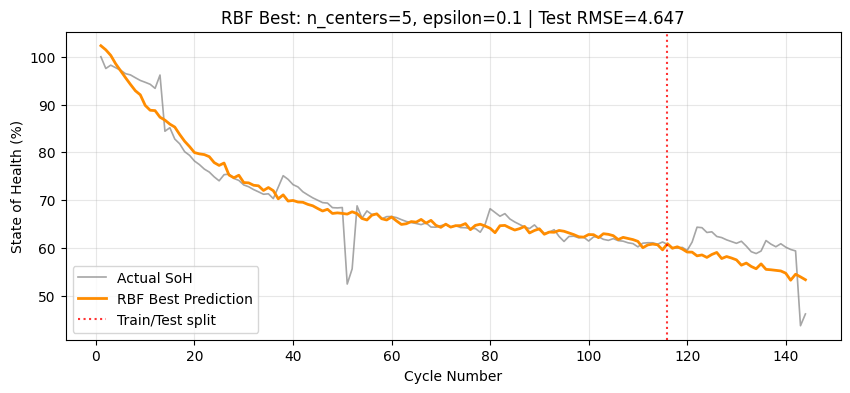

In [25]:
# Best RBF settings found from our study
rbf_best = RBFNetwork(n_centers=5, epsilon=0.1)
rbf_best.fit(X_train, y_train)

preds_best, actual_best, mse_best, rmse_best, mae_best = evaluate_rbf(
    rbf_best, X_test, y_test, scaler_y, "RBF Best (n_centers=5, epsilon=0.1)"
)

print(f"  Params: {rbf_best.count_parameters()}")

# Predictions over all cycles from the train-only model (no test-set leakage)
full_pred_rbf_best = scaler_y.inverse_transform(rbf_best.predict(X_scaled))
np.save(os.path.join(RESULTS_DIR, 'rbf_predictions.npy'), full_pred_rbf_best)

# Plot best RBF
plt.figure(figsize=(10, 4))
plt.plot(X, full_actual, label='Actual SoH', color='gray', linewidth=1.2, alpha=0.7)
plt.plot(X, full_pred_rbf_best, label='RBF Best Prediction', color='darkorange', linewidth=2)
plt.axvline(x=X[split, 0], color='red', linestyle=':', alpha=0.8, label='Train/Test split')
plt.xlabel('Cycle Number')
plt.ylabel('State of Health (%)')
plt.title(f'RBF Best: n_centers=5, epsilon=0.1 | Test RMSE={rmse_best:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(IMAGES_DIR, 'rbf_best.png'), dpi=150, bbox_inches='tight')
plt.show()

## Part 4 — Final Comparison: FC-FFNN vs RBF

### Evaluation Metrics

**Root Mean Squared Error (RMSE):**
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (\hat{y}_i - y_i)^2}$$

**Mean Absolute Error (MAE):**
$$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |\hat{y}_i - y_i|$$

RMSE penalizes large errors more heavily (due to squaring). MAE is more robust to outliers.  
Both reported in SoH percentage points (%).

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load saved predictions from Parts 2 and 3
cycles       = np.load(os.path.join(RESULTS_DIR, 'cycles.npy'))
actual_soh   = np.load(os.path.join(RESULTS_DIR, 'actual_soh.npy'))
ffnn_preds   = np.load(os.path.join(RESULTS_DIR, 'fcffnn_predictions.npy'))
rbf_preds    = np.load(os.path.join(RESULTS_DIR, 'rbf_predictions.npy'))

print(f"Cycles shape     : {cycles.shape}")
print(f"Actual SoH shape : {actual_soh.shape}")
print(f"FFNN preds shape : {ffnn_preds.shape}")
print(f"RBF preds shape  : {rbf_preds.shape}")

Cycles shape     : (144, 1)
Actual SoH shape : (144, 1)
FFNN preds shape : (144, 1)
RBF preds shape  : (144, 1)


In [27]:
# Use last 20% as test set (same split as before)
split = int(0.8 * len(cycles))

params_ffnn = model.count_parameters()
params_rbf  = rbf_best.count_parameters()

# Full data metrics
mse_ffnn_full  = mean_squared_error(actual_soh, ffnn_preds)
mse_rbf_full   = mean_squared_error(actual_soh, rbf_preds)
rmse_ffnn_full = np.sqrt(mse_ffnn_full)
rmse_rbf_full  = np.sqrt(mse_rbf_full)
mae_ffnn_full  = mean_absolute_error(actual_soh, ffnn_preds)
mae_rbf_full   = mean_absolute_error(actual_soh, rbf_preds)

# Test set metrics
rmse_ffnn_test = np.sqrt(mean_squared_error(actual_soh[split:], ffnn_preds[split:]))
rmse_rbf_test  = np.sqrt(mean_squared_error(actual_soh[split:], rbf_preds[split:]))
mae_ffnn_test  = mean_absolute_error(actual_soh[split:], ffnn_preds[split:])
mae_rbf_test   = mean_absolute_error(actual_soh[split:], rbf_preds[split:])

print("\n" + "="*55)
print(f"{'Metric':<25} {'FC-FFNN':>12} {'RBF':>12}")
print("="*55)
print(f"{'RMSE (full data)':<25} {rmse_ffnn_full:>12.4f} {rmse_rbf_full:>12.4f}")
print(f"{'RMSE (test set)':<25} {rmse_ffnn_test:>12.4f} {rmse_rbf_test:>12.4f}")
print(f"{'MAE  (full data)':<25} {mae_ffnn_full:>12.4f} {mae_rbf_full:>12.4f}")
print(f"{'MAE  (test set)':<25} {mae_ffnn_test:>12.4f} {mae_rbf_test:>12.4f}")
print(f"{'Parameters':<25} {params_ffnn:>12} {params_rbf:>12}")
print(f"{'Training time':<25} {'~5 sec':>12} {'<0.1 sec':>12}")
print(f"{'Training method':<25} {'Backprop':>12} {'Least Sq.':>12}")
print("="*55)


Metric                         FC-FFNN          RBF
RMSE (full data)                2.7908       3.1685
RMSE (test set)                 3.9845       4.6467
MAE  (full data)                1.5716       2.1384
MAE  (test set)                 2.6117       4.0273
Parameters                        6401           11
Training time                   ~5 sec     <0.1 sec
Training method               Backprop    Least Sq.


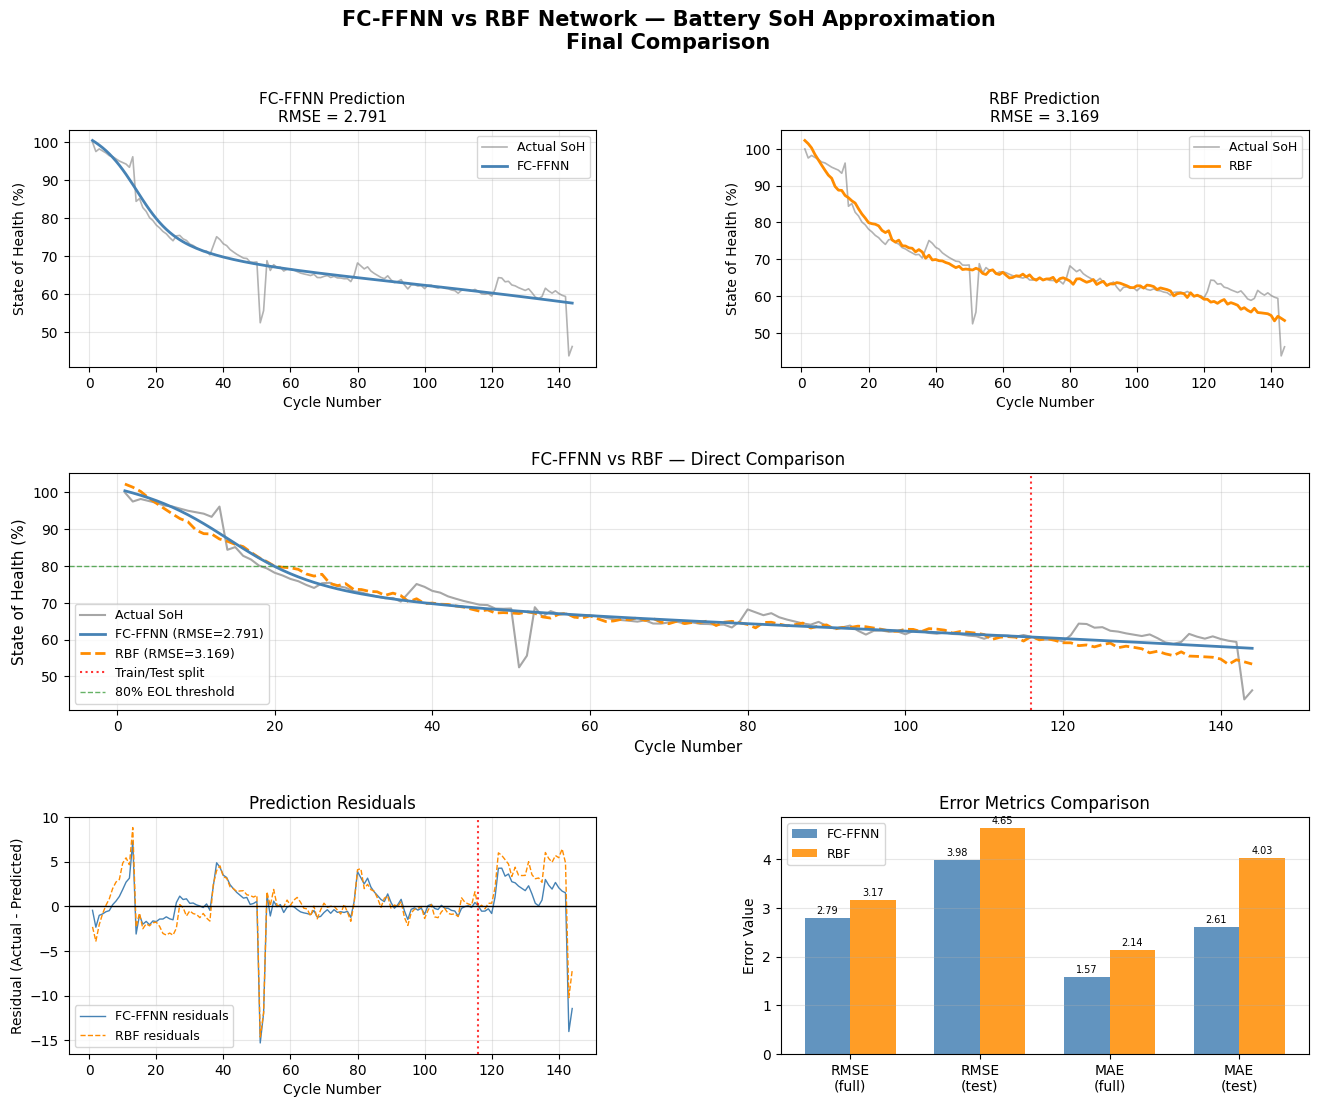

In [28]:
fig = plt.figure(figsize=(16, 12))
fig.suptitle('FC-FFNN vs RBF Network — Battery SoH Approximation\nFinal Comparison',
             fontsize=15, fontweight='bold', y=0.98)

gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# --- Plot 1: FC-FFNN prediction (full) ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(cycles, actual_soh, color='gray', linewidth=1.2, alpha=0.6, label='Actual SoH')
ax1.plot(cycles, ffnn_preds, color='steelblue', linewidth=2, label='FC-FFNN')
ax1.set_xlabel('Cycle Number')
ax1.set_ylabel('State of Health (%)')
ax1.set_title(f'FC-FFNN Prediction\nRMSE = {rmse_ffnn_full:.3f}', fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# --- Plot 2: RBF prediction (full) ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(cycles, actual_soh, color='gray', linewidth=1.2, alpha=0.6, label='Actual SoH')
ax2.plot(cycles, rbf_preds, color='darkorange', linewidth=2, label='RBF')
ax2.set_xlabel('Cycle Number')
ax2.set_ylabel('State of Health (%)')
ax2.set_title(f'RBF Prediction\nRMSE = {rmse_rbf_full:.3f}', fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

# --- Plot 3: Both on same axes ---
ax3 = fig.add_subplot(gs[1, :])
ax3.plot(cycles, actual_soh, color='gray', linewidth=1.5, alpha=0.7, label='Actual SoH', zorder=1)
ax3.plot(cycles, ffnn_preds, color='steelblue', linewidth=2, label=f'FC-FFNN (RMSE={rmse_ffnn_full:.3f})', zorder=3)
ax3.plot(cycles, rbf_preds, color='darkorange', linewidth=2, linestyle='--', label=f'RBF (RMSE={rmse_rbf_full:.3f})', zorder=2)
ax3.axvline(x=cycles[split], color='red', linestyle=':', linewidth=1.5, alpha=0.8, label='Train/Test split')
ax3.axhline(y=80, color='green', linestyle='--', linewidth=1, alpha=0.6, label='80% EOL threshold')
ax3.set_xlabel('Cycle Number', fontsize=11)
ax3.set_ylabel('State of Health (%)', fontsize=11)
ax3.set_title('FC-FFNN vs RBF — Direct Comparison', fontsize=12)
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3)

# --- Plot 4: Residuals FC-FFNN ---
ax4 = fig.add_subplot(gs[2, 0])
residuals_ffnn = actual_soh.flatten() - ffnn_preds.flatten()
residuals_rbf  = actual_soh.flatten() - rbf_preds.flatten()
ax4.plot(cycles, residuals_ffnn, color='steelblue', linewidth=1, label='FC-FFNN residuals')
ax4.plot(cycles, residuals_rbf,  color='darkorange', linewidth=1, linestyle='--', label='RBF residuals')
ax4.axhline(y=0, color='black', linewidth=1)
ax4.axvline(x=cycles[split], color='red', linestyle=':', linewidth=1.5, alpha=0.8)
ax4.set_xlabel('Cycle Number')
ax4.set_ylabel('Residual (Actual - Predicted)')
ax4.set_title('Prediction Residuals')
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.3)

# --- Plot 5: Bar chart comparison ---
ax5 = fig.add_subplot(gs[2, 1])
metrics   = ['RMSE\n(full)', 'RMSE\n(test)', 'MAE\n(full)', 'MAE\n(test)']
ffnn_vals = [rmse_ffnn_full, rmse_ffnn_test, mae_ffnn_full, mae_ffnn_test]
rbf_vals  = [rmse_rbf_full,  rmse_rbf_test,  mae_rbf_full,  mae_rbf_test]
x = np.arange(len(metrics))
w = 0.35
bars1 = ax5.bar(x - w/2, ffnn_vals, w, label='FC-FFNN', color='steelblue', alpha=0.85)
bars2 = ax5.bar(x + w/2, rbf_vals,  w, label='RBF',     color='darkorange', alpha=0.85)
ax5.set_xticks(x)
ax5.set_xticklabels(metrics)
ax5.set_ylabel('Error Value')
ax5.set_title('Error Metrics Comparison')
ax5.legend(fontsize=9)
ax5.grid(True, alpha=0.3, axis='y')
for bar in bars1:
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=7)
for bar in bars2:
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=7)

plt.savefig(os.path.join(IMAGES_DIR, 'final_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

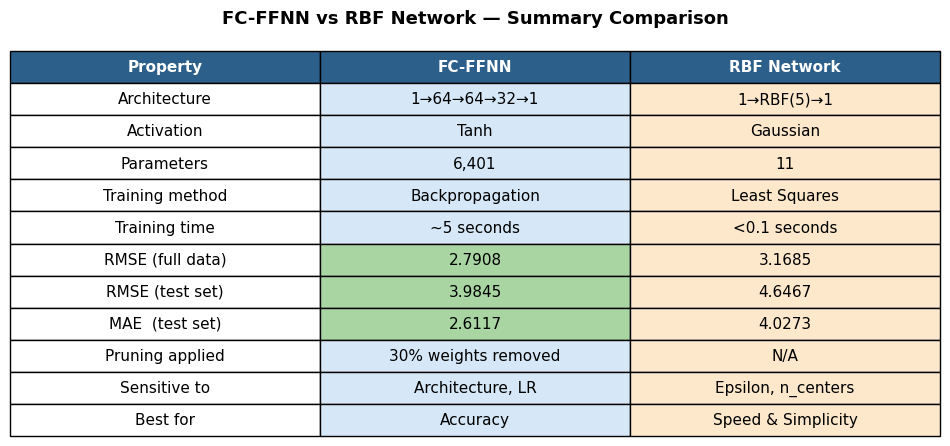

In [29]:
fig2, ax = plt.subplots(figsize=(12, 5))
ax.axis('off')

table_data = [
    ['Property',           'FC-FFNN',              'RBF Network'],
    ['Architecture',       '1→64→64→32→1',         '1→RBF(5)→1'],
    ['Activation',         'Tanh',                  'Gaussian'],
    ['Parameters',         f'{params_ffnn:,}',      f'{params_rbf:,}'],
    ['Training method',    'Backpropagation',        'Least Squares'],
    ['Training time',      '~5 seconds',            '<0.1 seconds'],
    ['RMSE (full data)',   f'{rmse_ffnn_full:.4f}', f'{rmse_rbf_full:.4f}'],
    ['RMSE (test set)',    f'{rmse_ffnn_test:.4f}', f'{rmse_rbf_test:.4f}'],
    ['MAE  (test set)',    f'{mae_ffnn_test:.4f}',  f'{mae_rbf_test:.4f}'],
    ['Pruning applied',    '30% weights removed',   'N/A'],
    ['Sensitive to',       'Architecture, LR',      'Epsilon, n_centers'],
    ['Best for',           'Accuracy',              'Speed & Simplicity'],
]

table = ax.table(
    cellText=table_data[1:],
    colLabels=table_data[0],
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(11)

# Style header row
for j in range(3):
    table[0, j].set_facecolor('#2c5f8a')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Style FC-FFNN column
for i in range(1, len(table_data)):
    table[i, 1].set_facecolor('#d6e8f7')

# Style RBF column
for i in range(1, len(table_data)):
    table[i, 2].set_facecolor('#fde8cc')

# Highlight winner rows (RMSE/MAE)
for i in [6, 7, 8]:
    ffnn_val = float(table_data[i][1])
    rbf_val  = float(table_data[i][2])
    if ffnn_val < rbf_val:
        table[i, 1].set_facecolor('#a8d5a2')  # green = winner
    else:
        table[i, 2].set_facecolor('#a8d5a2')

ax.set_title('FC-FFNN vs RBF Network — Summary Comparison',
             fontsize=13, fontweight='bold', pad=20)

plt.savefig(os.path.join(IMAGES_DIR, 'comparison_table.png'), dpi=150, bbox_inches='tight')
plt.show()

## Results & Conclusion

Both models are trained on the first 80% of cycles (115) and evaluated on the last 20% (29 cycles never seen during training). Full-data metrics are printed in the table above.

| Property | FC-FFNN | RBF (K=5, ε=0.1) |
|---|---|---|
| Architecture | 1→64→64→32→1 | 1→RBF(5)→1 |
| Parameters | 6,401 | 11 |
| Training | Backpropagation (Adam) | K-means + least squares |
| RMSE (test) | **3.984** | 4.647 |
| MAE (test) | **2.612** | 4.027 |
| RMSE (test) after 30% pruning + fine-tune | 3.964 | N/A |

### Conclusion
- **FC-FFNN generalizes better** to the unseen later cycles: lower test RMSE (3.98 vs 4.65) and MAE (2.61 vs 4.03 SoH percentage points).
- **RBF is far more compact**: 11 parameters (~580× fewer) solved in closed form, with no iterative training. It still reaches a reasonable test error.
- **RBF is fragile to its hyperparameters**: with too many centers or too large an ε the design matrix becomes ill-conditioned and test RMSE explodes past 200. The FC-FFNN was stable across all architectures tested (RMSE 3.98–4.35).
- **Pruning**: removing 30% of FC-FFNN weights and fine-tuning for 300 epochs caused no accuracy loss (test RMSE 3.98 → 3.96), so the network is heavily over-parameterized for this 1-D problem.
- The test set lies at the end of the degradation curve, so this is an *extrapolation* test. Both models have their largest errors there.